# PyTorch Fundamentals: Follow-Along Notebook

This is a live-coding notebook. Start with the TODO cells incomplete and write the missing code together during class.

## Core path

The class is successful when we can:

1. create and reshape tensors,
2. calculate a gradient with autograd,
3. define an `nn.Module`,
4. load Fashion-MNIST mini-batches,
5. perform one parameter update,
6. train and evaluate the model.

## Stretch path

If time remains, we will:

7. plot learning curves,
8. inspect confident mistakes,
9. save and reload the model.

Do not rush the core path to complete every section. Understanding one complete training loop is the priority.

> **Important:** do not use **Run all** at the beginning. TODO cells are intentionally incomplete and should be filled sequentially.

## Suggested three-hour pace

| Time | Target |
|---|---|
| 0–15 min | Setup and device check |
| 15–40 min | Tensors, shapes, and matrix multiplication |
| 40–60 min | Autograd and gradient clearing |
| 60–85 min | Build and test `FashionMLP` |
| 85–105 min | Fashion-MNIST and DataLoaders |
| 105–125 min | One complete parameter update |
| 125–135 min | Break |
| 135–170 min | Training loop, evaluation loop, and test result |
| Remaining time | Learning curves, mistakes, or saving the model |

## 0. Colab setup

Run this cell first. Google Colab normally includes PyTorch, NumPy, and Matplotlib, so the helper installs only missing packages.

If packages are installed, wait for the cell to finish before running the imports.

In [1]:
import importlib.util
import subprocess
import sys

required_packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
}

missing_packages = [
    package_name
    for module_name, package_name in required_packages.items()
    if importlib.util.find_spec(module_name) is None
]

if missing_packages:
    print("Installing:", ", ".join(missing_packages))
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *missing_packages]
    )
    print("Installation complete.")
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
%matplotlib inline

from pathlib import Path
import random

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
torch.set_printoptions(precision=4, sci_mode=False)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


### TODO 1: Select the available device

Use this priority:

1. CUDA GPU
2. Apple MPS
3. CPU

**Checkpoint:** printing `device` should show `cuda`, `mps`, or `cpu`.

In [3]:
torch.cuda.is_available()
torch.backends.mps.is_available()

False

In [5]:
# TODO: Select CUDA, MPS, or CPU and store it in `device`.
if torch.cuda.is_available():
    device = torch.cuda("cuda")
else:
    device = torch.device("cpu")
print("Selected device:", device)

Selected device: cpu


# Core 1: Tensors and shapes

## 1. Create three tensors

Create:

- a $2\times3$ integer tensor from a Python list,
- a $2\times3$ tensor of zeros,
- a $2\times3$ tensor of random values.

For each tensor, print its values, shape, and dtype.

In [12]:
# TODO: Create the three tensors.
l1 = [[1, 2, 3], [4, 5, 6]] # 2x3 array
from_list = torch.tensor(l1)

zeros = torch.zeros((2, 3))
random_values = torch.rand((2, 3))
random_values

# TODO: Print each tensor, its shape, and its dtype.

tensor([[0.9516, 0.0753, 0.8860],
        [0.5832, 0.3376, 0.8090]])

In [14]:
numpy_array = np.array([1.0, 2.0, 3.0])
tensor_np = torch.from_numpy(numpy_array)
tensor_np

tensor([1., 2., 3.], dtype=torch.float64)

In [ ]:
# one image - 28 x 28 x 1, 28 (H) x 28 (W) x 3 (C)
# 100 images - 100 (B, or N) x 28 x 28 x 1
# pytorch format - N x C x H x W, not in NHWC

## 2. Reshape a batch of images

A grayscale image batch has shape:

$$
(B,C,H,W)=(B,1,28,28).
$$

An MLP needs one vector per image:

$$
(B,1,28,28)\rightarrow(B,784).
$$

Create four random images and flatten every image without combining the batch dimension.

**Checkpoint:** the flattened shape should be `torch.Size([4, 784])`.

In [18]:
# TODO: Create a tensor with shape (4, 1, 28, 28).
images = torch.rand((4, 1, 28, 28))
print(images.shape)
flattened = images.reshape(4, 784)

# TODO: Flatten each image while preserving the batch dimension.


print("Original shape:", images.shape)
print("Flattened shape:", flattened.shape)

images = flattened.reshape(4, 28, 28)
print("Recreated shape:", images.shape)

torch.Size([4, 1, 28, 28])
Original shape: torch.Size([4, 1, 28, 28])
Flattened shape: torch.Size([4, 784])
Recreated shape: torch.Size([4, 28, 28])


## 3. Recreate a linear layer using matrix multiplication

For:

$$
Z=XW+b,
$$

use these shapes:

$$
X:(4,784),\qquad W:(784,128),\qquad b:(128,).
$$

Before coding: what should the shape of $Z$ be?

In [19]:
# TODO: Create X, W, and b with the specified shapes.
X = torch.rand((4, 784))
W = torch.rand((784, 256))
b = torch.rand(256)


# TODO: Calculate Z = X @ W + b.
Z = X @ W + b

print("Output shape:", Z.shape)

Output shape: torch.Size([4, 256])


In [23]:
lin = torch.nn.Linear(784, 256)
lin.weight.shape, lin.bias.shape
Z = lin(X)
Z.shape

torch.Size([4, 256])

In [ ]:
# [4, 256] + [4, 256]

# Core 2: Autograd

## 4. Calculate gradients automatically

Use:

$$
\widehat y=wx+b,\qquad L=(\widehat y-y)^2,
$$

with:

$$
w=2,\quad b=1,\quad x=3,\quad y=10.
$$

Create trainable tensors for $w$ and $b$, calculate the loss, and call `backward()`.

**Expected values:**

$$
\widehat y=7,\quad L=9,\quad
\frac{\partial L}{\partial w}=-18,\quad
\frac{\partial L}{\partial b}=-6.
$$

del_L/del_w = 2(wx + b - y)*x = 2 * (2 * 3 + 1 - 10) * 3 = -18
del_L/del_b = 2(wx + b - y) = -6


In [28]:
# TODO: Create w and b with gradient tracking enabled.
w = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
print(w.grad)
print(b.grad)

# TODO: Create x and target.

X = torch.tensor(3.0)
target = torch.tensor(10.0)

# TODO: Calculate prediction and squared-error loss.
prediction = w * X + b
loss = (prediction - target) ** 2
# TODO: Run backpropagation.
loss.backward()

print("Prediction:", prediction.item())
print("Loss:", loss.item())
print("dL/dw:", w.grad.item())
print("dL/db:", b.grad.item())

None
None
Prediction: 7.0
Loss: 9.0
dL/dw: -18.0
dL/db: -6.0


### Why gradients must be cleared

PyTorch accumulates gradients in `.grad`. A training loop therefore clears previous gradients before the next backward pass.

Clear the gradients of $w$ and $b$ manually. Later, the optimizer will do this through `optimizer.zero_grad()`.

In [ ]:
# batch gradient descent - 4 samples
# 1. forward pass
# 2. loss calculation
# 3. gradient computation (.backward())
# important step = clear the grads
# 4. update the weight

In [29]:
# TODO: Set the stored gradients of w and b back to zero.
w.grad.zero_()
b.grad.zero_()

print("w gradient after clearing:", w.grad.item())
print("b gradient after clearing:", b.grad.item())

w gradient after clearing: 0.0
b gradient after clearing: 0.0


# Core 3: Build an `nn.Module`

## 5. Define the Fashion-MNIST MLP

Build:

$$
784\rightarrow128\rightarrow64\rightarrow10.
$$

Use:

- `nn.Flatten`
- `nn.Linear`
- `nn.ReLU`
- `nn.Sequential`

`__init__()` creates the layers. `forward()` describes how an input uses them.

In [30]:
class FashionMLP(nn.Module):
    def __init__(self):
        super().__init__()

        # TODO: Create a flatten layer.
        self.flatten = nn.Flatten()

        # TODO: Create 784 -> 128 -> 64 -> 10 with ReLU activations.
        self.layers = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        # TODO: Flatten x and pass it through the network.
        x = self.flatten(x)
        output = self.layers(x)
        return output

## 6. Test the model before training

Create the model on the selected device and pass eight fake images through it.

**Checkpoints:**

- input shape: `(8, 1, 28, 28)`
- output shape: `(8, 10)`
- parameter count: `109,386`

In [33]:
# TODO: Create FashionMLP and move it to the selected device.
model = FashionMLP()

# TODO: Create eight fake images on the same device.
dummy_images = torch.rand(8, 1, 28, 28, device=device)
dummy_logits = model(dummy_images)

# TODO: Run a forward pass.


trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print("Input shape:", dummy_images.shape)
print("Output shape:", dummy_logits.shape)
print("Trainable parameters:", f"{trainable_parameters:,}")

FashionMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)
Input shape: torch.Size([8, 1, 28, 28])
Output shape: torch.Size([8, 10])
Trainable parameters: 109,386


In [39]:
print(dummy_logits)
print()
print(torch.softmax(dummy_logits, dim=1))

probs = torch.softmax(dummy_logits, dim=1)
print(torch.sum(probs[0]))

tensor([[ 0.0395,  0.0425, -0.0621, -0.1213,  0.0442, -0.0915,  0.0551,  0.1218,
         -0.0622,  0.0570],
        [ 0.0294,  0.0570, -0.0668, -0.1360,  0.0469, -0.0798,  0.0525,  0.0816,
         -0.1044,  0.0390],
        [-0.0010, -0.0066, -0.0900, -0.1796,  0.0539, -0.0816,  0.0914,  0.0852,
         -0.0643,  0.0906],
        [ 0.0054, -0.0205, -0.0524, -0.1182,  0.0437, -0.0698,  0.0646,  0.1330,
         -0.0626,  0.0992],
        [-0.0161,  0.0481, -0.0465, -0.1187,  0.0243, -0.0798,  0.0782,  0.0830,
         -0.0646,  0.1467],
        [ 0.0281,  0.0262, -0.0432, -0.1099,  0.0446, -0.0661,  0.0608,  0.1129,
         -0.0623,  0.0676],
        [ 0.0600,  0.0475, -0.1159, -0.1108,  0.0274, -0.0913,  0.0710,  0.0712,
         -0.0796,  0.0689],
        [-0.0284,  0.0603, -0.0739, -0.1147,  0.0471, -0.0788,  0.0850,  0.1068,
         -0.0724,  0.0919]], grad_fn=<AddmmBackward0>)

tensor([[0.1035, 0.1038, 0.0935, 0.0881, 0.1040, 0.0908, 0.1051, 0.1124, 0.0935,
         0.1053],
 

## 7. Logits and cross-entropy

The final layer returns ten raw scores called logits. `nn.CrossEntropyLoss` expects:

- logits with shape $(B,10)$,
- integer class labels with shape $(B,)$.

Do not add softmax inside the model. Cross-entropy applies the required log-softmax calculation internally.

In [41]:
example_logits = torch.tensor([
    [2.0, 1.0, 0.1],
    [0.2, 0.3, 2.4],
])
example_labels = torch.tensor([0, 2])

# TODO: Create CrossEntropyLoss and calculate the example loss.
loss_function = nn.CrossEntropyLoss()
example_loss = loss_function(example_logits, example_labels)

# TODO: Convert logits to probabilities only for interpretation.
example_probabilities = torch.softmax(example_logits, dim=1)

print("Probabilities:\n", example_probabilities)
print("Loss:", example_loss.item())

Probabilities:
 tensor([[0.6590, 0.2424, 0.0986],
        [0.0898, 0.0993, 0.8109]])
Loss: 0.3133453130722046


# Core 4: Dataset and DataLoader

## 8. Download Fashion-MNIST

This setup is provided so class time stays focused on PyTorch concepts. `ToTensor()` converts images to tensors with shape `(1, 28, 28)` and scales pixels to $[0,1]$.

In [42]:
DATA_DIR = Path("data")
transform = transforms.ToTensor()

complete_train_dataset = datasets.FashionMNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transform,
)
test_dataset = datasets.FashionMNIST(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=transform,
)

train_dataset, validation_dataset = random_split(
    complete_train_dataset,
    lengths=[55_000, 5_000],
    generator=torch.Generator().manual_seed(SEED),
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(validation_dataset))
print("Test examples:", len(test_dataset))

100%|██████████| 26.4M/26.4M [00:01<00:00, 20.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 304kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.60MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.0MB/s]

Training examples: 55000
Validation examples: 5000
Test examples: 10000


## 9. Create mini-batches

Create three `DataLoader` objects with batch size 128.

- Shuffle the training data.
- Do not shuffle validation or test data.

Before coding: why is shuffling useful during training but unnecessary during evaluation?

In [43]:
BATCH_SIZE = 128

# TODO: Create train_loader with shuffle=True.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# TODO: Create validation_loader and test_loader with shuffle=False.
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)
batch_images, batch_labels = next(iter(train_loader))

print("Image batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)
print("Number of training batches:", len(train_loader))

Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
Number of training batches: 430


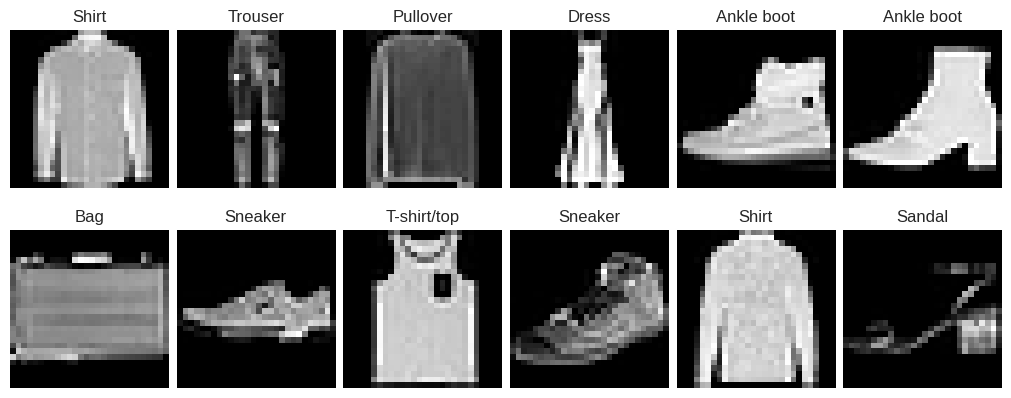

In [44]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

fig, axes = plt.subplots(2, 6, figsize=(10, 4), constrained_layout=True)
for ax, image, label in zip(axes.ravel(), batch_images[:12], batch_labels[:12]):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label.item()])
    ax.axis("off")

plt.show()

# Core 5: One parameter update

## 10. Write the five essential operations

Create a fresh model, cross-entropy loss, and Adam optimizer. Then perform one update:

1. clear gradients,
2. forward pass,
3. calculate loss,
4. backward pass,
5. optimizer step.

Store a copy of the first-layer weights before the update and verify that they changed afterward.

In [49]:
# TODO: Create a fresh model, loss function, and Adam optimizer.
demo_model = FashionMLP().to(device)
loss_function = nn.CrossEntropyLoss()
demo_optimizer = torch.optim.Adam(demo_model.parameters(), lr=1e-2)

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

# TODO: Copy the first linear layer's weights before updating.
weight_before = demo_model.layers[0].weight.detach().clone()

# TODO: Perform the five training operations.
demo_optimizer.zero_grad()
batch_logits = model(images)
batch_loss = loss_function(batch_logits, labels)
batch_loss.backward()
demo_optimizer.step()

# TODO: Read the first-layer weights after the update.
weight_after = demo_model.layers[0].weight.detach().clone()

mean_weight_change = (weight_after - weight_before).abs().mean()

print("Logits shape:", batch_logits.shape)
print("Batch loss:", batch_loss.item())
print("Mean absolute weight change:", mean_weight_change.item())

Logits shape: torch.Size([128, 10])
Batch loss: 2.2984817028045654
Mean absolute weight change: 0.0


# Core 6: Reusable loops

## 11. Convert one update into one training epoch

Complete the function using the same five operations inside the batch loop.

Accumulate:

- `loss.item() * batch_size`
- the number of correct predictions
- the number of examples

Return average loss and accuracy for the complete epoch.

In [50]:
def train_one_epoch(model, data_loader, loss_function, optimizer, device):
    # TODO: Put the model in training mode.
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in data_loader:
        # TODO: Move the batch to the selected device.
        images = images.to(device)
        labels = labels.to(device)

        # TODO: Clear gradients, run forward, calculate loss,
        # run backward, and update parameters.
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()

        # TODO: Accumulate loss, correct predictions, and example count.
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    # TODO: Return average loss and accuracy.
    return total_loss / total_examples, total_correct/total_examples

## 12. Write the evaluation loop

Evaluation differs from training:

- use `model.eval()`,
- use `torch.no_grad()`,
- do not call `backward()`,
- do not call `optimizer.step()`.

In [51]:
def evaluate(model, data_loader, loss_function, device):
    # TODO: Put the model in evaluation mode.
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    # TODO: Disable gradient tracking.
    with torch.no_grad():
        for images, labels in data_loader:
            # TODO: Move data, run forward, and calculate loss.
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = loss_function(logits, labels)

            # TODO: Accumulate loss, correct predictions, and count.
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_examples += batch_size

    # TODO: Return average loss and accuracy.
    return total_loss / total_examples, total_correct/total_examples

## 13. Train for three epochs

Three epochs keep the follow-along session practical. More epochs can be run after class.

Create a fresh model so the one-batch experiment does not affect this training run.

In [54]:
# TODO: Create a fresh model, CrossEntropyLoss, and Adam optimizer.
model = FashionMLP().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 6
history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": [],
}

for epoch in range(1, EPOCHS + 1):
    # TODO: Run one training epoch.
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, loss_function, optimizer, device
    )


    # TODO: Evaluate on the validation loader.
    validation_loss, validation_accuracy = evaluate(
        model, validation_loader, loss_function, device
    )

    # TODO: Append all four values to history.
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f} | "
        f"train accuracy {train_accuracy:.3f} | "
        f"validation loss {validation_loss:.4f} | "
        f"validation accuracy {validation_accuracy:.3f}"
    )

Epoch 01/6 | train loss 0.6347 | train accuracy 0.779 | validation loss 0.4733 | validation accuracy 0.835
Epoch 02/6 | train loss 0.4166 | train accuracy 0.853 | validation loss 0.4148 | validation accuracy 0.850
Epoch 03/6 | train loss 0.3769 | train accuracy 0.866 | validation loss 0.3872 | validation accuracy 0.860
Epoch 04/6 | train loss 0.3491 | train accuracy 0.875 | validation loss 0.3830 | validation accuracy 0.861
Epoch 05/6 | train loss 0.3297 | train accuracy 0.881 | validation loss 0.3655 | validation accuracy 0.862
Epoch 06/6 | train loss 0.3148 | train accuracy 0.885 | validation loss 0.3618 | validation accuracy 0.867


## 14. Evaluate the test set

Use the completed `evaluate()` function. This completes the essential PyTorch workflow.

In [55]:
# TODO: Evaluate the trained model on test_loader.
test_loss, test_accuracy = evaluate(model, test_loader, loss_function, device)

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

Test loss: 0.3758
Test accuracy: 0.8644


# Core-path checkpoint

At this point, we have covered the minimum complete PyTorch workflow:

$$
\text{tensor}\rightarrow\text{DataLoader}\rightarrow
\text{model}\rightarrow\text{loss}\rightarrow
\text{backward}\rightarrow\text{optimizer step}.
$$

If class time is nearly over, stop here and reconstruct the training loop verbally. The remaining sections are valuable but optional for the first PyTorch session.

# Stretch 1: Plot learning curves

This plotting code is provided. Focus on interpretation:

- Is training loss decreasing?
- Does validation loss follow it?
- Is the train–validation gap growing?

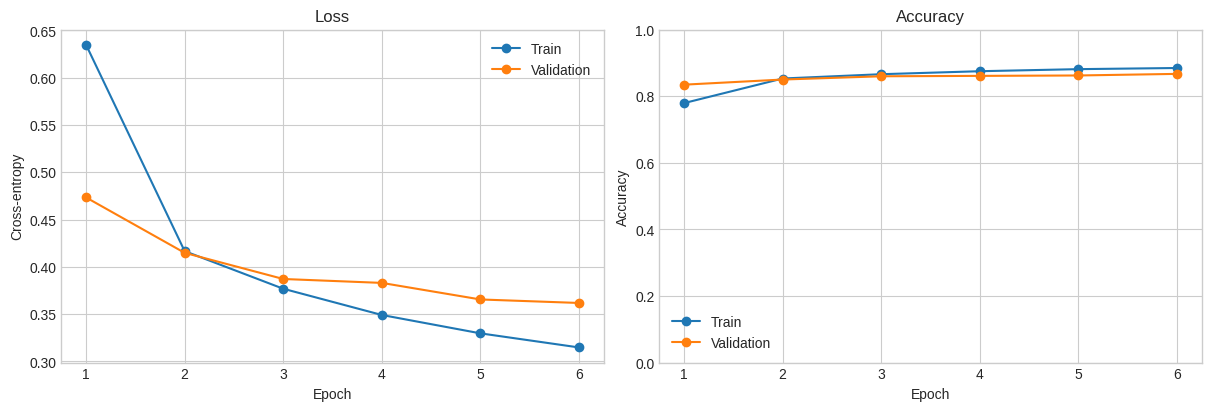

In [56]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, history["validation_loss"], marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()

axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Train")
axes[1].plot(epochs, history["validation_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.show()

# Stretch 2: Inspect confident mistakes

This helper code is provided because plotting is not the learning objective. Softmax is used after training to interpret logits as probabilities.

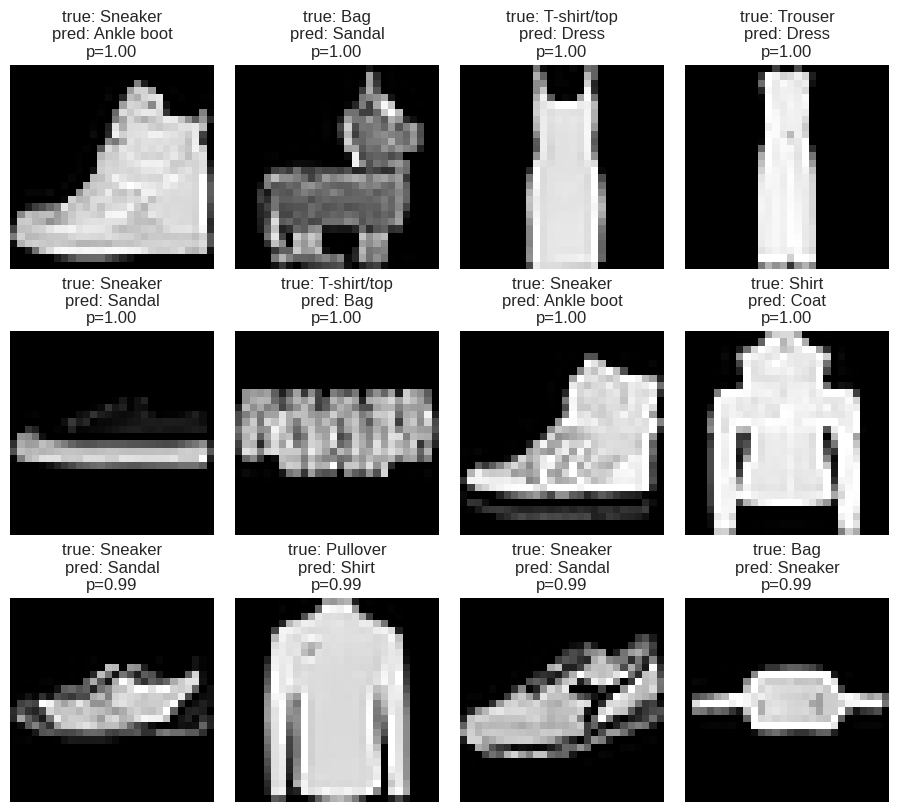

In [57]:
model.eval()
wrong_images = []
wrong_true = []
wrong_predicted = []
wrong_confidence = []

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(device))
        probabilities = torch.softmax(logits, dim=1).cpu()
        confidence, predictions = probabilities.max(dim=1)
        wrong = predictions != labels

        wrong_images.append(images[wrong])
        wrong_true.append(labels[wrong])
        wrong_predicted.append(predictions[wrong])
        wrong_confidence.append(confidence[wrong])

wrong_images = torch.cat(wrong_images)
wrong_true = torch.cat(wrong_true)
wrong_predicted = torch.cat(wrong_predicted)
wrong_confidence = torch.cat(wrong_confidence)

top_indices = torch.argsort(wrong_confidence, descending=True)[:12]

fig, axes = plt.subplots(3, 4, figsize=(9, 8), constrained_layout=True)
for ax, index in zip(axes.ravel(), top_indices):
    ax.imshow(wrong_images[index].squeeze(), cmap="gray")
    ax.set_title(
        f"true: {class_names[wrong_true[index]]}\n"
        f"pred: {class_names[wrong_predicted[index]]}\n"
        f"p={wrong_confidence[index]:.2f}"
    )
    ax.axis("off")

plt.show()

# Stretch 3: Save and reload parameters

Save `model.state_dict()`. Then create a new `FashionMLP`, load the state dictionary, switch to evaluation mode, and predict one test image.

In [58]:
model.state_dict()

OrderedDict([('layers.0.weight',
              tensor([[ 0.0930,  0.1170, -0.0391,  ..., -0.1702, -0.2095, -0.1911],
                      [-0.1418, -0.0645, -0.1732,  ..., -0.2079, -0.2367, -0.2248],
                      [ 0.0016,  0.0374,  0.1526,  ..., -0.0609, -0.1127,  0.0120],
                      ...,
                      [-0.0042, -0.0041, -0.0201,  ...,  0.0331, -0.1211, -0.1137],
                      [-0.0298, -0.0306,  0.0565,  ..., -0.0320, -0.0263,  0.0186],
                      [-0.0085, -0.1219, -0.0974,  ...,  0.1033,  0.1552,  0.0756]])),
             ('layers.0.bias',
              tensor([ 0.1488, -0.1290,  0.2319, -0.0349,  0.1002,  0.2667,  0.0032, -0.0973,
                      -0.1530, -0.0289,  0.3079, -0.0902, -0.1923, -0.0857,  0.2856,  0.3248,
                       0.1560, -0.1834, -0.0223, -0.2842,  0.1451, -0.2016, -0.0294, -0.0283,
                      -0.3191, -0.0920,  0.0374,  0.0072,  0.2419, -0.0718, -0.0861, -0.0239,
                       0.2

In [ ]:
MODEL_PATH = Path("fashion_mnist_mlp_state_dict.pth")

# TODO: Save the trained model's state_dict.
torch.save(model.state_dict(), MODEL_PATH)

# TODO: Create a new FashionMLP on the same device.
loaded_model = FashionMLP().to(device)

# TODO: Load the state_dict using map_location and weights_only=True.
state_dict = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)
loaded_model.load_state_dict(state_dict)

# TODO: Load the weights into the new model and call eval().
loaded_model.eval()

sample_image, sample_label = test_dataset[0]

# TODO: Disable gradients and predict the sample image.
with torch.no_grad():
    sample_logits = loaded_model(sample_image.unsqueeze(0).to(device))
    sample_prediction = sample_logits.argmax(dim=1).item()

print("Actual class:", class_names[sample_label])
print("Predicted class:", class_names[sample_prediction])

# Final retrieval

Explain the following without looking at the earlier cells:

1. What does a tensor's shape tell us?
2. What does `requires_grad=True` do?
3. Why are old gradients cleared?
4. What belongs in `__init__()` and what belongs in `forward()`?
5. Why does `CrossEntropyLoss` receive logits?
6. What is the relationship between `Dataset` and `DataLoader`?
7. What are the five operations in one training update?
8. How does evaluation differ from training?
9. What is stored inside `state_dict`?

## After class

Complete any unfinished stretch sections, increase training to five epochs, and compare CPU and GPU runtime if both are available.